<a href="https://colab.research.google.com/github/phiribrian873/ATM-Final/blob/main/ATM_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!git clone https://github.com/phiribrian873/ATM-Final.git
%cd ATM-Final
!ls


Cloning into 'ATM-Final'...
remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (7/7), done.
remote: Total 7 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (7/7), 28.94 KiB | 4.13 MiB/s, done.
/content/ATM-Final
atm_dqn_assignment.py  test_results.csv  training_log.csv
atm_dqn.pt	       test_summary.csv


In [2]:

import pandas as pd

print("ATM DQN PROJECT RESULTS")

print("\nTEST SUMMARY")
summary = pd.read_csv("test_summary.csv")
display(summary)

print("\nTRAINING LOG")
training = pd.read_csv("training_log.csv")
display(training.tail(10))

print("\nTEST RESULTS")
results = pd.read_csv("test_results.csv")
display(results.head(10))


ATM DQN PROJECT RESULTS

TEST SUMMARY


,Unnamed: 0,total_cost,total_cost.1,replenishments,replenishments.1,cash_availability_pct,cash_availability_pct.1,unmet_demand,unmet_demand.1,avg_end_cash,avg_end_cash.1,max_consecutive_shortage_days,max_consecutive_shortage_days.1
0,NaN,mean,std,mean,std,mean,std,mean,std,mean,std,mean,std
1,policy,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Cash threshold,11.4675,0.577,7.3,0.483,100.0,0.0,0.0,0.0,4.9613,0.121,0.0,0.0
3,DQN,11.3514,1.1927,7.0,0.0,98.0357,1.0137,0.1808,0.1194,3.093,0.1701,0.9,0.3162
4,Fixed schedule,12.3673,0.1226,8.0,0.0,100.0,0.0,0.0,0.0,5.1992,0.146,0.0,0.0



TRAINING LOG


,episode,reward
340,341,-8.487968
341,342,-8.013045
342,343,-7.445830
343,344,-18.482043
344,345,-10.945878
345,346,-10.087346
346,347,-8.972447
347,348,-8.143038
348,349,-7.024527
349,350,-8.247320



TEST RESULTS


,total_cost,replenishments,cash_availability_pct,unmet_demand,avg_end_cash,max_consecutive_shortage_days,policy
0,11.105783,7,96.428571,0.143416,3.232294,1,DQN
1,11.993908,7,98.214286,0.258611,2.959819,1,DQN
2,13.252421,7,96.428571,0.372843,3.139388,1,DQN
3,10.676331,7,98.214286,0.111282,3.091984,1,DQN
4,10.030087,7,98.214286,0.039125,3.155602,1,DQN
5,12.001462,7,98.214286,0.237381,3.213884,1,DQN
6,12.986163,7,98.214286,0.327881,3.341435,1,DQN
7,9.629701,7,100.000000,0.000000,3.130596,0,DQN
8,11.121797,7,98.214286,0.175999,2.875228,1,DQN
9,10.716604,7,98.214286,0.141620,2.789711,1,DQN


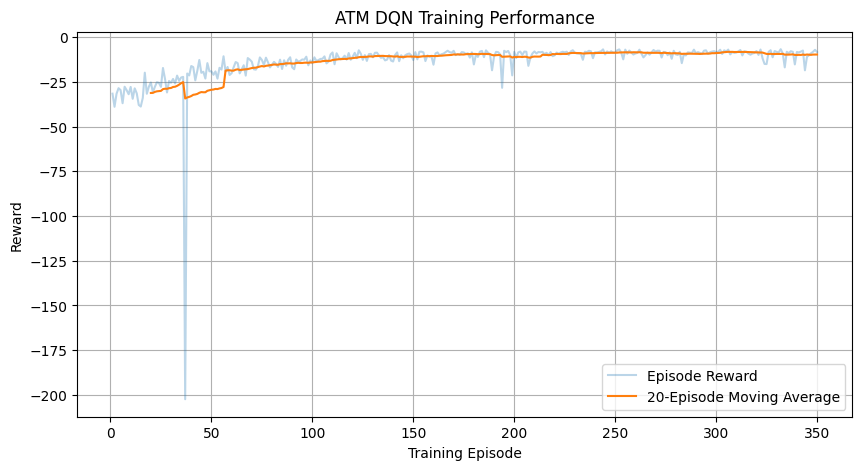

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

training = pd.read_csv("training_log.csv")

training["moving_average"] = (
    training["reward"]
    .rolling(window=20)
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    training["episode"],
    training["reward"],
    alpha=0.3,
    label="Episode Reward"
)

plt.plot(
    training["episode"],
    training["moving_average"],
    label="20-Episode Moving Average"
)

plt.xlabel("Training Episode")
plt.ylabel("Reward")
plt.title("ATM DQN Training Performance")
plt.legend()
plt.grid(True)
plt.show()


In [4]:

import pandas as pd

training = pd.read_csv("training_log.csv")

training["moving_average"] = (
    training["reward"].rolling(20).mean()
)

print("Last 10 moving averages:")
print(training["moving_average"].tail(10))

print("\nAverage reward, episodes 251-300:")
print(training["reward"].iloc[250:300].mean())

print("\nAverage reward, episodes 301-350:")
print(training["reward"].iloc[300:350].mean())


Last 10 moving averages:
340   -9.841439
341   -9.898672
342   -9.683248
343   -9.860976
344   -9.658610
345   -9.753562
346   -9.839426
347   -9.687002
348   -9.652461
349   -9.655116
Name: moving_average, dtype: float64

Average reward, episodes 251-300:
-8.828017233940185

Average reward, episodes 301-350:
-9.228736632460135


In [5]:

import pandas as pd

results = pd.read_csv("test_results.csv")

dqn = results[results["policy"] == "DQN"]

print("DQN EVALUATION STABILITY")

print("Number of evaluations:", len(dqn))

for metric in [
    "total_cost",
    "cash_availability_pct",
    "unmet_demand"
]:
    print("\n", metric)
    print("Mean:", round(dqn[metric].mean(), 4))
    print("Standard deviation:",
          round(dqn[metric].std(), 4))
    print("Minimum:", round(dqn[metric].min(), 4))
    print("Maximum:", round(dqn[metric].max(), 4))


DQN EVALUATION STABILITY
Number of evaluations: 10

 total_cost
Mean: 11.3514
Standard deviation: 1.1927
Minimum: 9.6297
Maximum: 13.2524

 cash_availability_pct
Mean: 98.0357
Standard deviation: 1.0137
Minimum: 96.4286
Maximum: 100.0

 unmet_demand
Mean: 0.1808
Standard deviation: 0.1194
Minimum: 0.0
Maximum: 0.3728
